# Week 3: EI sensitivity to alpha

Compact update of the [week-2 sweep](../week_2/05_all_functions_ei_alpha_sweep.ipynb), using observations through week 3 and 1,000,000 candidates per function. Sweep `xi = alpha * std(y)` with the GP and pool fixed. Matérn 3/2 is the suggestion kernel; RBF is comparison-only. No objective evaluations or saved suggestions are changed.

In [1]:
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, RBF, WhiteKernel

from bayesian_bbo import CONFIG, FUNCTION_SPECS, load_observations
from bayesian_bbo.optimisation import BayesianOptimizer, OptimisationConfig

WEEK, N_CANDIDATES, BATCH_SIZE = 3, 1_000_000, 10_000
FUNCTION_IDS = tuple(FUNCTION_SPECS)
ALPHA_VALUES = np.unique(np.r_[np.linspace(0, 1, 50), 0.01, 0.1, 0.3])
LENGTH_CAPS = CONFIG["length_caps"]
data_root = next((p.resolve() for p in map(Path, ('../../data', 'data', '../data'))
                  if (p / 'function_1').is_dir()), None)
if data_root is None:
    raise FileNotFoundError('Could not find the data directory from the notebook working directory.')
print(f'Training through week {WEEK}; {N_CANDIDATES:,} candidates; data: {data_root}')

Training through week 3; 1,000,000 candidates; data: /home/pabloncho/repositories/bayesian-bbo/data


## Fit once, reuse predictions

`BayesianOptimizer.suggest_ei_sweep()` handles candidate generation, batched prediction and EI maximization. Each seeded optimizer uses the same pool across kernels and alphas, excluding observed inputs, and fits its GP once. Each row records the pool EI maximizer, its mean, uncertainty and distance to the nearest observation; it is not a guaranteed global maximum. Percentages use the observed-output standard deviation.

In [2]:
def make_kernel(name, dimension, cap):
    options = dict(length_scale=np.ones(dimension), length_scale_bounds=(1e-3, cap))
    base = RBF(**options) if name == 'RBF' else Matern(**options, nu=1.5)
    return ConstantKernel(1.0, (1e-3, 1e3)) * base + WhiteKernel(1e-5, (1e-8, 1e1))


records = []
for function_id in FUNCTION_IDS:
    observations = load_observations(data_root, function_id, up_to_week=WEEK)
    target_std = float(np.std(observations.outputs))
    if target_std == 0:
        raise ValueError(f'Function {function_id}: alpha scaling requires nonconstant outputs.')
    for name in ('RBF', 'Matérn 3/2'):
        kernel = make_kernel(name, observations.dimension, LENGTH_CAPS[function_id])
        optimizer = BayesianOptimizer(observations, OptimisationConfig(
            budget=1, candidates=N_CANDIDATES, kernel=kernel, xi=0, best=observations.best_output))
        suggestions = optimizer.suggest_ei_sweep(ALPHA_VALUES * target_std, batch_size=BATCH_SIZE)
        for alpha, (candidate, mean, std, score) in zip(ALPHA_VALUES, suggestions):
            xi = float(alpha * target_std)
            records.append(dict(function_id=function_id, kernel=name, alpha=float(alpha), xi=xi,
                                candidate=tuple(candidate), mean=mean, std=std,
                                max_ei=score, target_std=target_std,
                                best_observed=observations.best_output,
                                nearest_distance=float(np.linalg.norm(observations.inputs - candidate, axis=1).min()),
                                max_ei_pct=100 * score / target_std, std_pct=100 * std / target_std))
        print(f'Function {function_id}, {name}: requested {N_CANDIDATES:,} candidates')
results = pd.DataFrame(records)

/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


Function 1, RBF: requested 1,000,000 candidates


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


Function 1, Matérn 3/2: requested 1,000,000 candidates


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


...

Function 7, Matérn 3/2: requested 1,000,000 candidates


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 7 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


Function 8, RBF: requested 1,000,000 candidates


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 7 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


Function 8, Matérn 3/2: requested 1,000,000 candidates


## EI and selected uncertainty

Solid lines: maximum EI (left axis). Dashed lines: uncertainty at the selected point (right axis). Both are percentages of `std(y)`; axes have separate limits. Uncertainty can jump when the selected point changes. Falling EI is expected as the improvement threshold rises, not evidence that smaller alpha performs better.

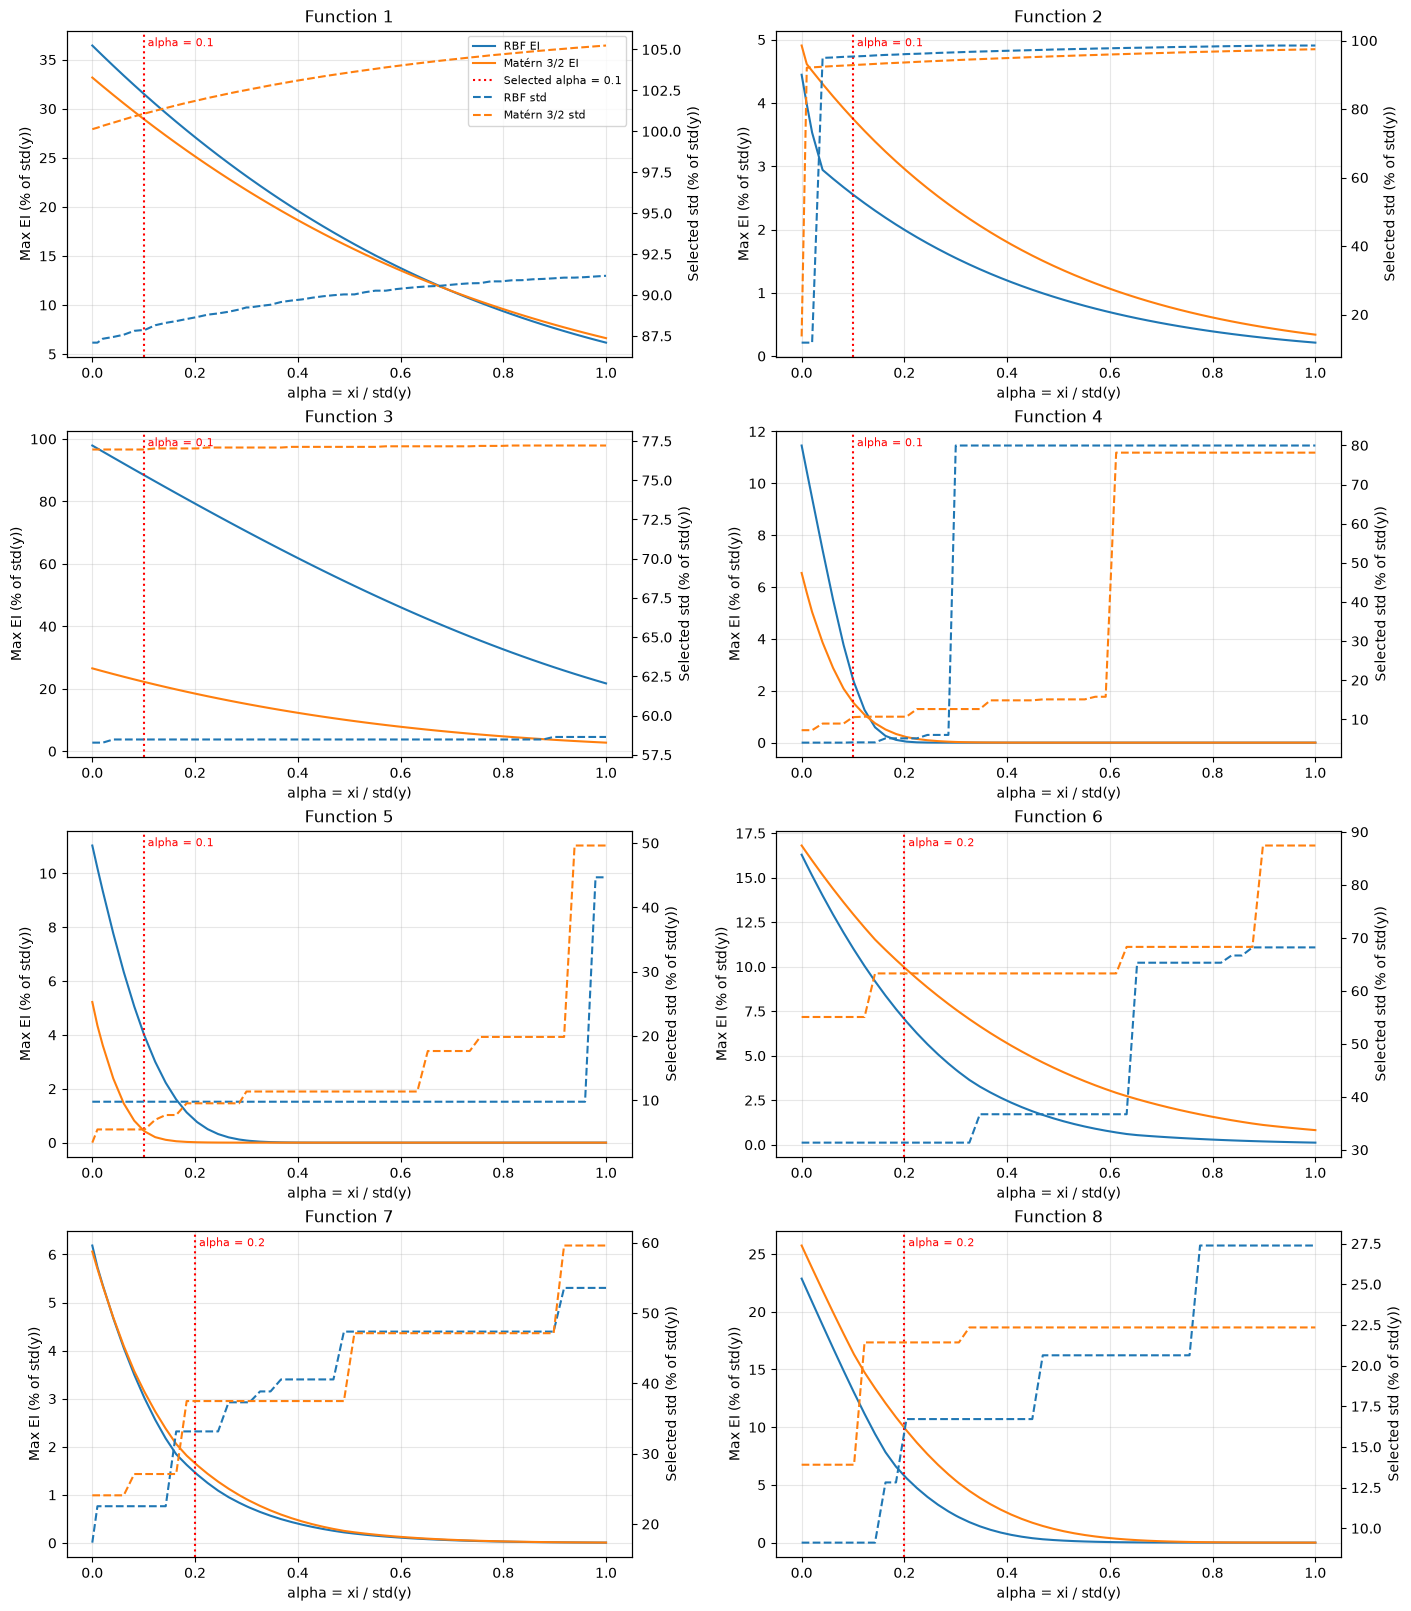

In [3]:
SELECTED_ALPHAS = {function_id: 0.1 if function_id <= 5 else 0.2 for function_id in FUNCTION_IDS}
figure, axes = plt.subplots(4, 2, figsize=(14, 16), constrained_layout=True)
for function_id, ax in zip(FUNCTION_IDS, axes.flat):
    right = ax.twinx()
    for name, rows in results[results.function_id == function_id].groupby('kernel', sort=False):
        line, = ax.plot(rows.alpha, rows.max_ei_pct, label=f'{name} EI')
        right.plot(rows.alpha, rows.std_pct, '--', color=line.get_color(), label=f'{name} std')
    ax.set(title=f'Function {function_id}', xlabel='alpha = xi / std(y)', ylabel='Max EI (% of std(y))')
    right.set_ylabel('Selected std (% of std(y))')
    alpha = SELECTED_ALPHAS[function_id]
    ax.axvline(alpha, color='red', linestyle=':', label=f'Selected alpha = {alpha:g}')
    ax.text(alpha, 0.98, f' alpha = {alpha:g}', transform=ax.get_xaxis_transform(),
            color='red', va='top', fontsize=8)
    ax.grid(alpha=0.3)
    if function_id == FUNCTION_IDS[0]:
        handles, labels = ax.get_legend_handles_labels()
        other_handles, other_labels = right.get_legend_handles_labels()
        ax.legend(handles + other_handles, labels + other_labels, fontsize=8)
display(figure)
plt.close(figure)

## Matérn 3/2: selected-candidate diagnostics

One dashboard per function, using the existing sweep results without refitting. Mean and best observed share an output scale; standard deviation is shown separately. Candidate coordinates lie in `[0, 1)`; nearest distance is Euclidean distance in input space and is not directly comparable across dimensions. Xi and maximum EI use output units. Markers show the tested alpha values; connecting lines are visual guides, not evaluations between them. Best observed is constant because this sweep does not evaluate the objective.

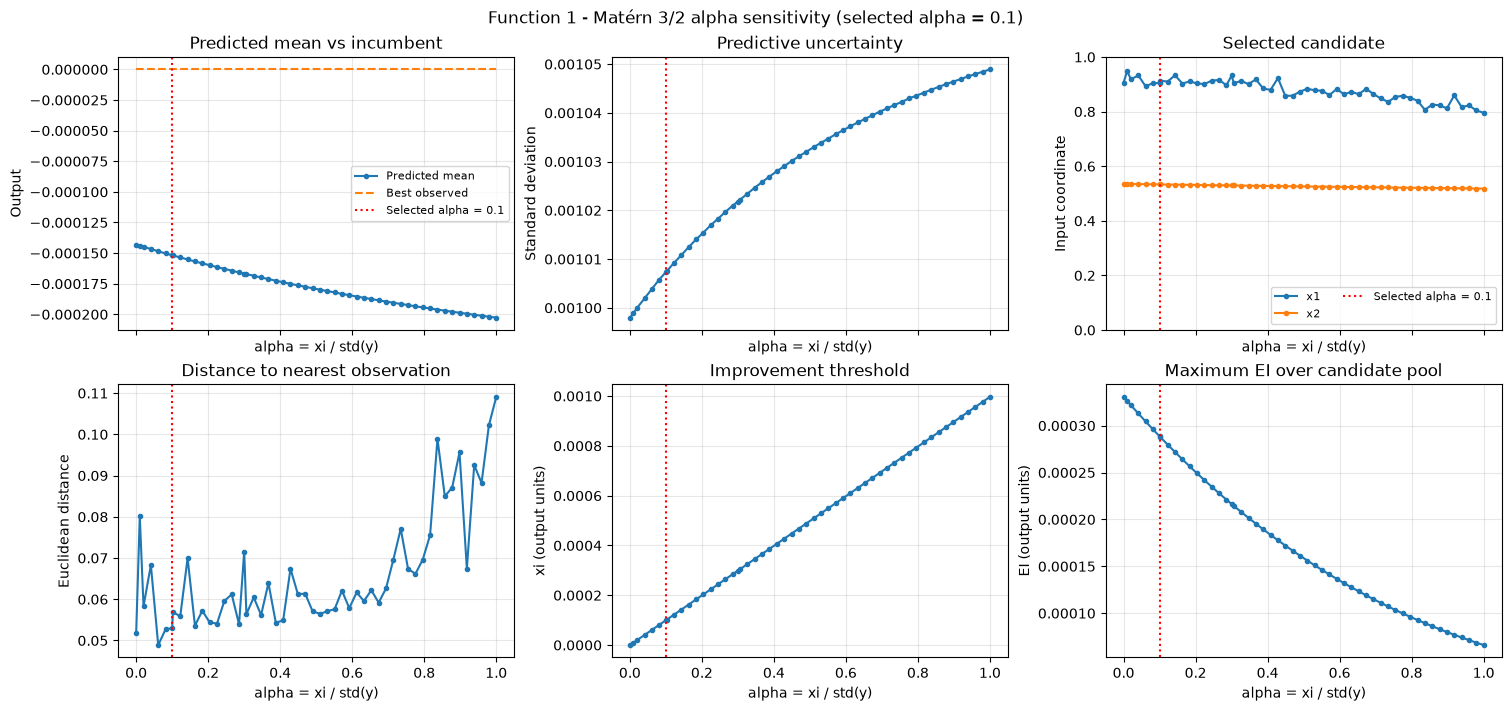

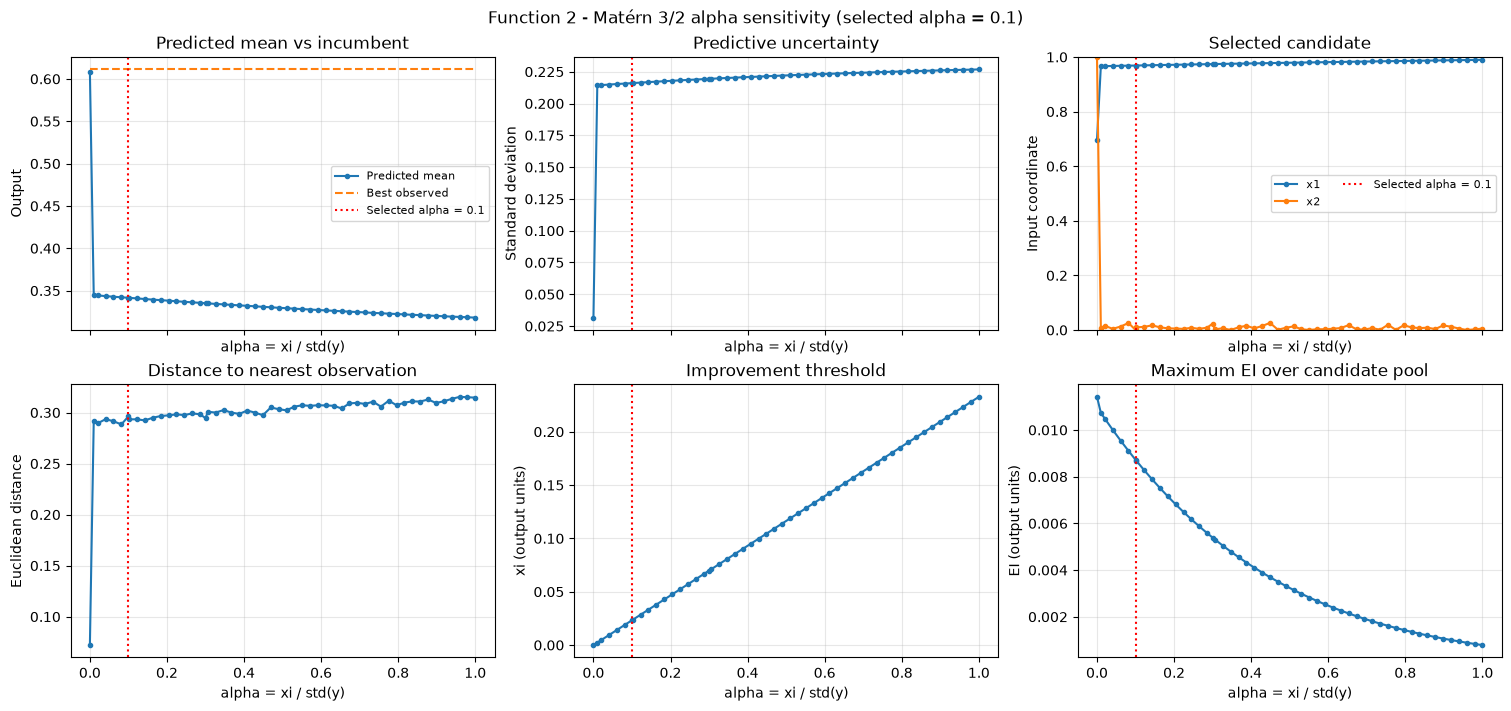

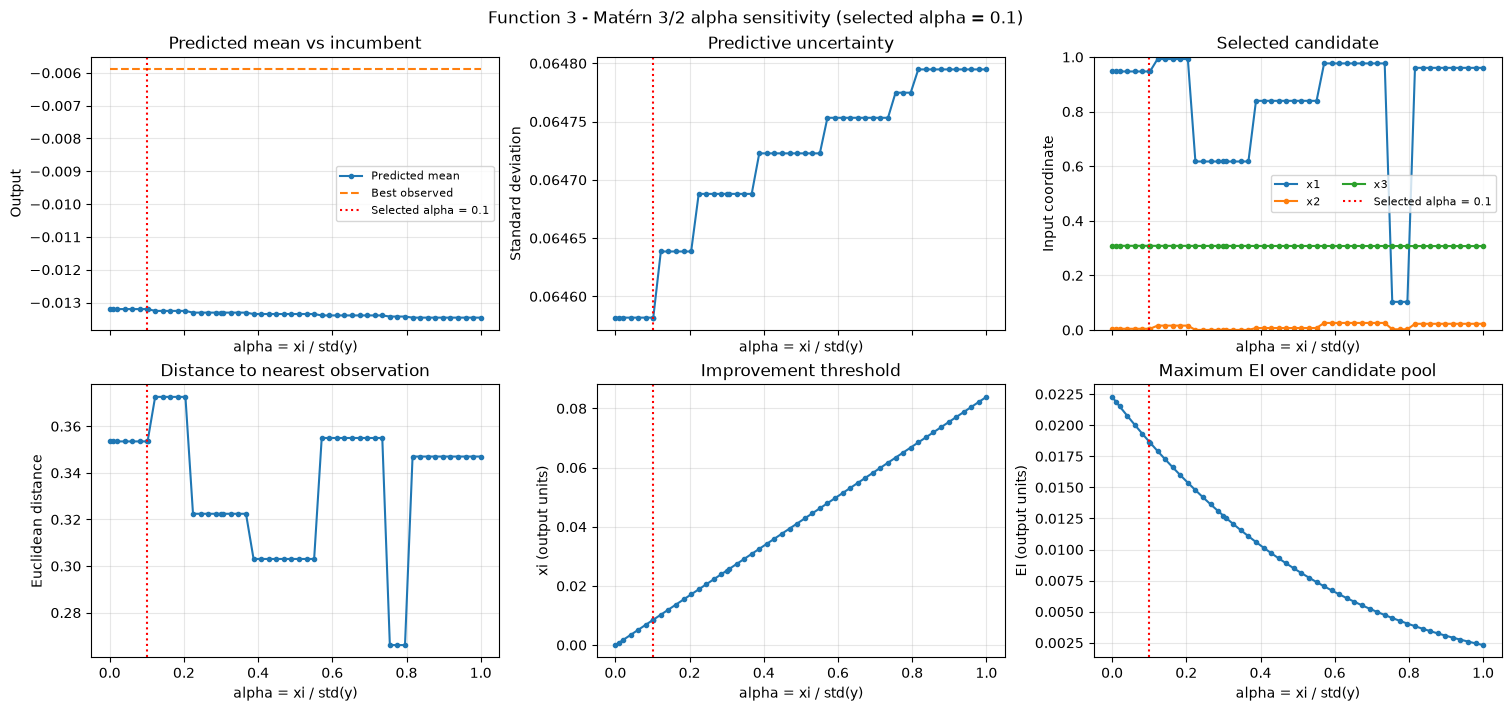

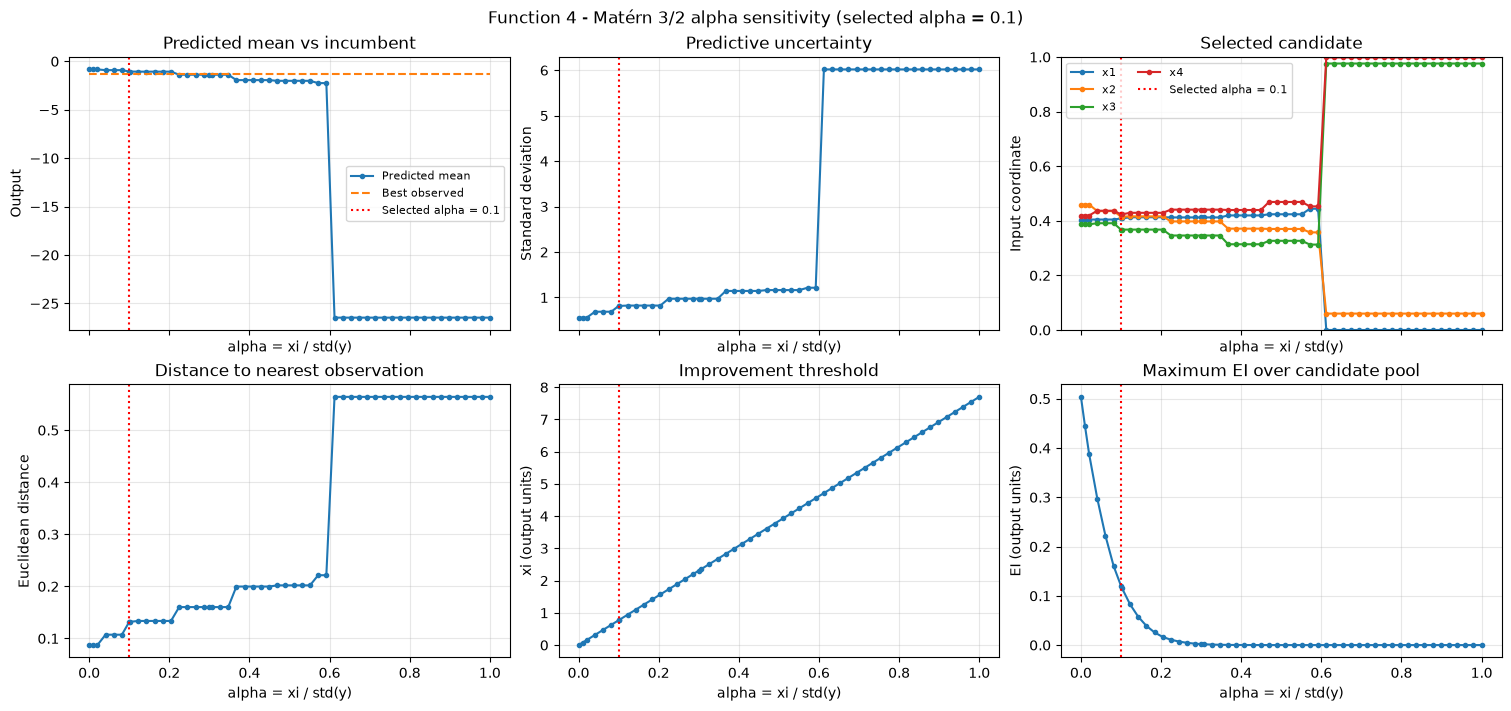

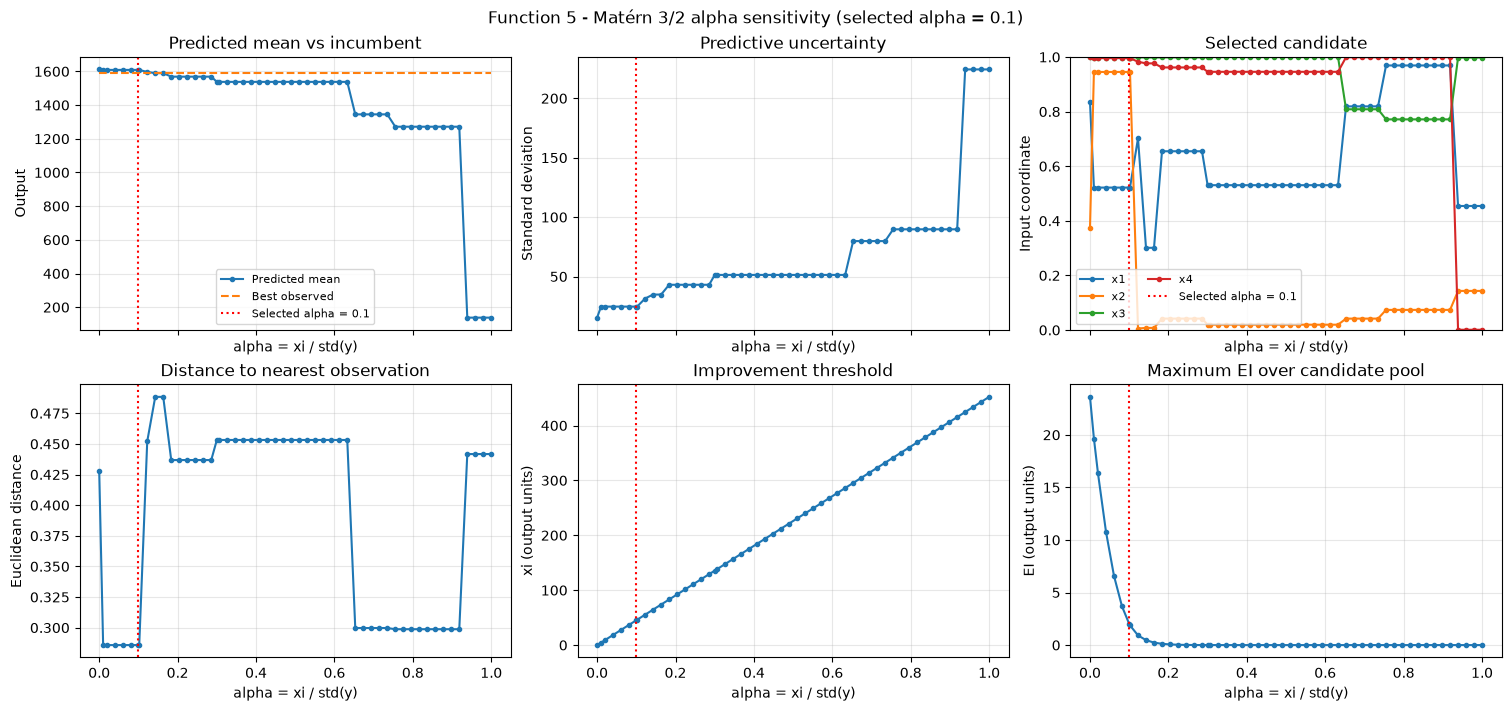

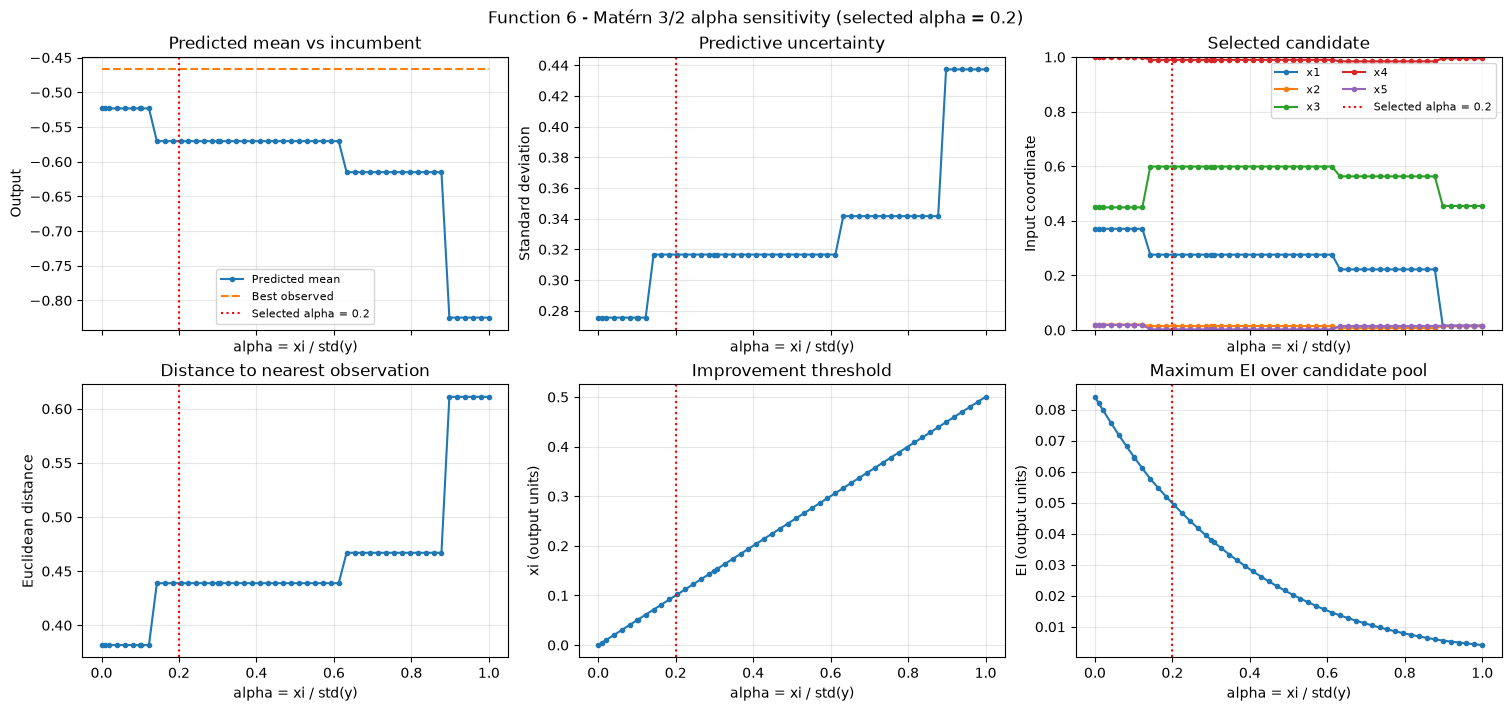

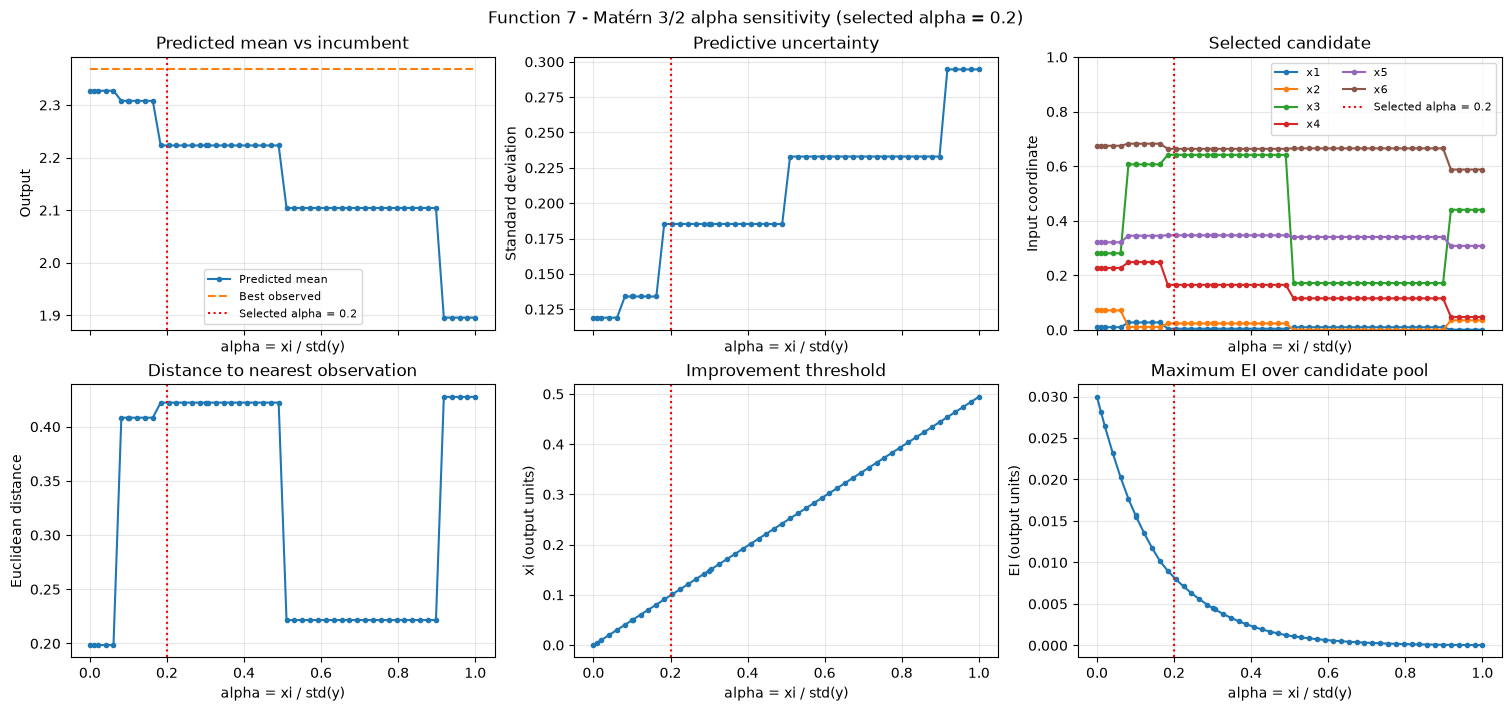

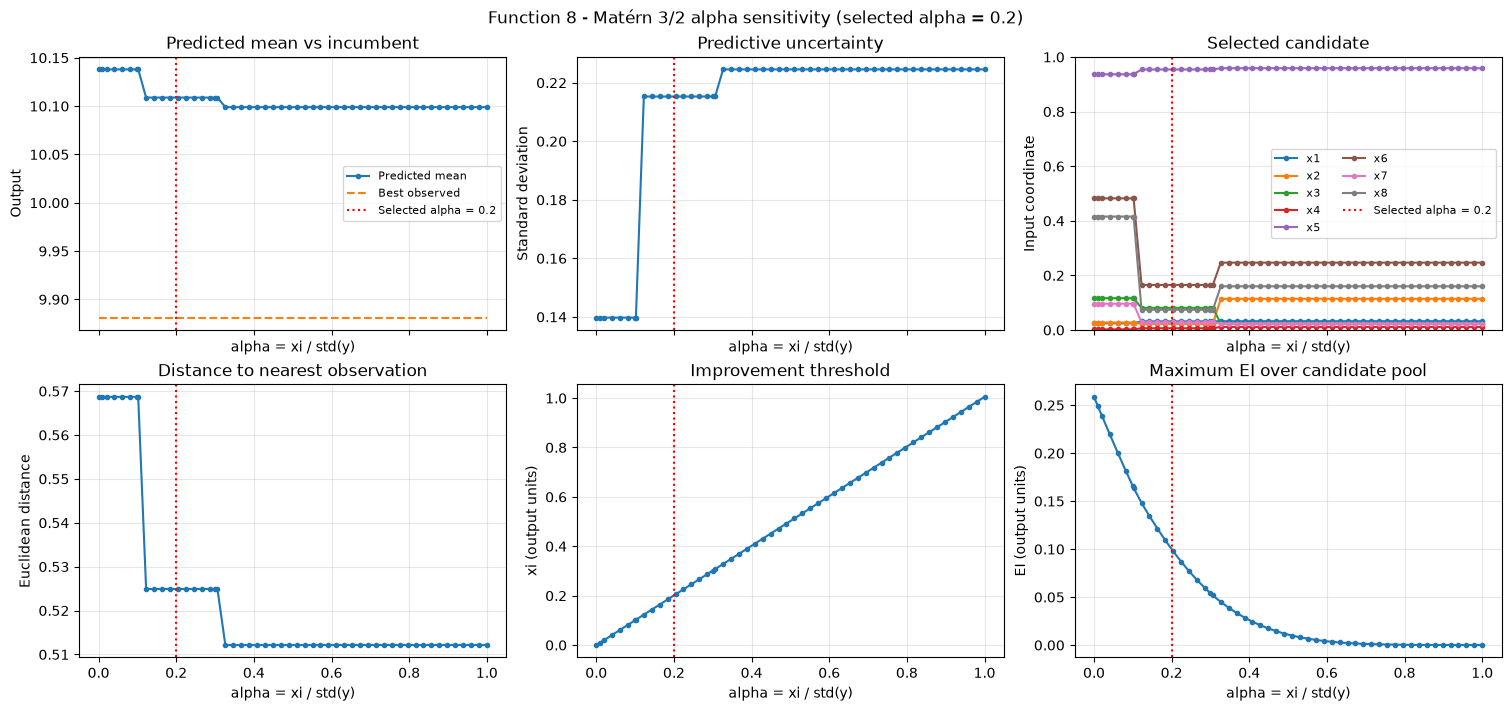

In [4]:
matern_results = results[results.kernel == 'Matérn 3/2']
for function_id, rows in matern_results.groupby('function_id', sort=True):
    rows = rows.sort_values('alpha')
    figure, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True, constrained_layout=True)
    output_ax, std_ax, candidate_ax, distance_ax, xi_ax, ei_ax = axes.flat
    output_ax.plot(rows.alpha, rows['mean'], '.-', label='Predicted mean')
    output_ax.plot(rows.alpha, rows.best_observed, '--', label='Best observed')
    output_ax.set(title='Predicted mean vs incumbent', ylabel='Output')
    coordinates = np.asarray(rows.candidate.tolist())
    for j in range(coordinates.shape[1]):
        candidate_ax.plot(rows.alpha, coordinates[:, j], '.-', label=f'x{j + 1}')
    candidate_ax.set(title='Selected candidate', ylabel='Input coordinate', ylim=(0, 1))
    for ax, column, title, ylabel in (
        (std_ax, 'std', 'Predictive uncertainty', 'Standard deviation'),
        (distance_ax, 'nearest_distance', 'Distance to nearest observation', 'Euclidean distance'),
        (xi_ax, 'xi', 'Improvement threshold', 'xi (output units)'),
        (ei_ax, 'max_ei', 'Maximum EI over candidate pool', 'EI (output units)'),
    ):
        ax.plot(rows.alpha, rows[column], '.-')
        ax.set(title=title, ylabel=ylabel)
    alpha = SELECTED_ALPHAS[function_id]
    for ax in axes.flat:
        ax.axvline(alpha, color='red', linestyle=':', label=f'Selected alpha = {alpha:g}')
        ax.set_xlabel('alpha = xi / std(y)')
        ax.grid(alpha=0.3)
    output_ax.legend(fontsize=8)
    candidate_ax.legend(fontsize=8, ncol=2)
    figure.suptitle(f'Function {function_id} - Matérn 3/2 alpha sensitivity (selected alpha = {alpha:g})')
    display(figure)
    plt.close(figure)

## Recommended xi values

For the next Matérn 3/2 suggestions, use alpha = 0.1 for Functions 1-5 and 0.2 for Functions 6-8, based on visual inspection. Compute `xi = alpha * std(y)` from observations through week 3. These are heuristic choices, not validated optima; the table calculates xi exactly, without rounding alpha to the sweep grid.

In [5]:
recommended_xi = (
    results.loc[results.kernel == 'Matérn 3/2', ['function_id', 'target_std']]
    .drop_duplicates().sort_values('function_id').reset_index(drop=True)
)
recommended_xi['alpha'] = recommended_xi.function_id.map(SELECTED_ALPHAS)
recommended_xi['xi'] = recommended_xi.alpha * recommended_xi.target_std
XI_VALUES = recommended_xi.set_index('function_id')['xi'].to_dict()
display(recommended_xi[['function_id', 'alpha', 'target_std', 'xi']])
print(f'XI_VALUES = {XI_VALUES}')

,function_id,alpha,target_std,xi
0,1,0.1,0.000997,0.000100
1,2,0.1,0.232669,0.023267
2,3,0.1,0.083915,0.008392
3,4,0.1,7.701378,0.770138
4,5,0.1,452.161761,45.216176
5,6,0.2,0.500277,0.100055
6,7,0.2,0.494300,0.098860
7,8,0.2,1.004889,0.200978


XI_VALUES = {1: 9.96663063489224e-05, 2: 0.023266943506776105, 3: 0.008391546020766163, 4: 0.7701378406861035, 5: 45.21617607937864, 6: 0.10005542729396313, 7: 0.0988599706959349, 8: 0.20097788613469525}
